In [10]:
# Import core data manipulation and numerical libraries

import pandas as pd
import numpy as np

# Import data visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Import system and configuration management utilities
import os
import yaml

# Configure display options and plot themes for clean visualization
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


Load Configuration

In [11]:
import os
import yaml

# Automatically find or define correct paths based on current working directory
if os.path.exists("../config.yaml"):
    with open("../config.yaml", "r", encoding="utf-8") as f:
        config = yaml.safe_load(f)
    print("Configuration loaded from config.yaml")
else:
    # Fallback paths adjusted whether running from root or python/ subfolder
    base_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
    config = {
        'paths': {
            'raw_data': os.path.join(base_dir, 'data', 'raw', 'aqi.csv'),
            'processed_data': os.path.join(base_dir, 'data', 'processed', 'cleaned_aqi.csv')
        }
    }
    print("Using robust fallback configuration paths.")

print("Resolved Raw Data Path:", config['paths']['raw_data'])

Configuration loaded from config.yaml
Resolved Raw Data Path: ../data/raw/aqi.csv


Data Loading  Raw Dataset and Undrstanding 

In [13]:
import os
import pandas as pd

# Define explicit fallback paths depending on your current working directory
possible_paths = [
    "../data/raw/aqi.csv",
    "../../data/raw/aqi.csv",
    "data/raw/aqi.csv",
    "C:/Users/prath/india-aqi-analysis/data/raw/aqi.csv"
]

raw_data_path = None
for path in possible_paths:
    if os.path.exists(path):
        raw_data_path = path
        break

if raw_data_path is None:
    raise FileNotFoundError("Could not locate aqi.csv. Please check your data folder location.")

print(f"Successfully found dataset at: {raw_data_path}")

# Load the raw AQI CSV dataset
df = pd.read_csv(raw_data_path)

print(f"Dataset Shape: {df.shape[0]:,} rows and {df.shape[1]} columns")
print("\nFirst 5 Rows of Raw Data:")
display(df.head())

print("\nDataset Information & Data Types:")
df.info()

Successfully found dataset at: ../../data/raw/aqi.csv
Dataset Shape: 235,785 rows and 9 columns

First 5 Rows of Raw Data:


,date,state,area,number_of_monitoring_stations,prominent_pollutants,aqi_value,air_quality_status,unit,note
0,30-04-2025,Maharashtra,Amravati,2,PM10,78,Satisfactory,number_of_monitoring_stations in Absolute Numb...,NaN
1,30-04-2025,Bihar,Purnia,1,CO,56,Satisfactory,number_of_monitoring_stations in Absolute Numb...,NaN
2,30-04-2025,Madhya Pradesh,Katni,1,O3,98,Satisfactory,number_of_monitoring_stations in Absolute Numb...,NaN
3,30-04-2025,Chhattisgarh,Tumidih,1,PM10,103,Moderate,number_of_monitoring_stations in Absolute Numb...,NaN
4,30-04-2025,Assam,Byrnihat,1,PM2.5,61,Satisfactory,number_of_monitoring_stations in Absolute Numb...,NaN



Dataset Information & Data Types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 235785 entries, 0 to 235784
Data columns (total 9 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   date                           235785 non-null  object 
 1   state                          235785 non-null  object 
 2   area                           235785 non-null  object 
 3   number_of_monitoring_stations  235785 non-null  int64  
 4   prominent_pollutants           235785 non-null  object 
 5   aqi_value                      235785 non-null  int64  
 6   air_quality_status             235785 non-null  object 
 7   unit                           235785 non-null  object 
 8   note                           0 non-null       float64
dtypes: float64(1), int64(2), object(6)
memory usage: 16.2+ MB


In [14]:
df.head()

,date,state,area,number_of_monitoring_stations,prominent_pollutants,aqi_value,air_quality_status,unit,note
0,30-04-2025,Maharashtra,Amravati,2,PM10,78,Satisfactory,number_of_monitoring_stations in Absolute Numb...,NaN
1,30-04-2025,Bihar,Purnia,1,CO,56,Satisfactory,number_of_monitoring_stations in Absolute Numb...,NaN
2,30-04-2025,Madhya Pradesh,Katni,1,O3,98,Satisfactory,number_of_monitoring_stations in Absolute Numb...,NaN
3,30-04-2025,Chhattisgarh,Tumidih,1,PM10,103,Moderate,number_of_monitoring_stations in Absolute Numb...,NaN
4,30-04-2025,Assam,Byrnihat,1,PM2.5,61,Satisfactory,number_of_monitoring_stations in Absolute Numb...,NaN


In [15]:
df.tail()

,date,state,area,number_of_monitoring_stations,prominent_pollutants,aqi_value,air_quality_status,unit,note
235780,01-04-2022,Bihar,Arrah,1,PM10,210,Poor,number_of_monitoring_stations in Absolute Numb...,NaN
235781,01-04-2022,Rajasthan,Jaipur,3,"PM2.5,PM10",158,Moderate,number_of_monitoring_stations in Absolute Numb...,NaN
235782,01-04-2022,Maharashtra,Chandrapur,2,PM2.5,201,Poor,number_of_monitoring_stations in Absolute Numb...,NaN
235783,01-04-2022,Uttar Pradesh,Varanasi,4,PM10,128,Moderate,number_of_monitoring_stations in Absolute Numb...,NaN
235784,01-04-2022,Odisha,Brajrajnagar,1,O3,270,Poor,number_of_monitoring_stations in Absolute Numb...,NaN


Data Cleaning & Preprocessing Function

In [16]:
def clean_aqi_data(df_input):
    """
    Cleans the raw AQI dataset by:
    1. Dropping redundant null columns ('note').
    2. Parsing date strings into standardized datetime format (dayfirst=True).
    3. Stripping leading/trailing whitespaces from string/categorical columns.
    4. Casting numerical features and handling missing values with median imputation.
    5. Removing duplicate records.
    """
    df_clean = df_input.copy()
    
    # Drop fully null 'note' column if present
    if 'note' in df_clean.columns:
        df_clean = df_clean.drop(columns=['note'])
        
    # Parse dates with dayfirst format (DD-MM-YYYY)
    if 'date' in df_clean.columns:
        df_clean['date'] = pd.to_datetime(df_clean['date'], dayfirst=True, errors='coerce')
        
    # Standardize string columns
    str_cols = ['state', 'area', 'prominent_pollutants', 'air_quality_status', 'unit']
    for col in str_cols:
        if col in df_clean.columns:
            df_clean[col] = df_clean[col].astype(str).str.strip()
            
    # Handle numerical columns
    if 'aqi_value' in df_clean.columns:
        df_clean['aqi_value'] = pd.to_numeric(df_clean['aqi_value'], errors='coerce')
        df_clean['aqi_value'] = df_clean['aqi_value'].fillna(df_clean['aqi_value'].median())
        
    if 'number_of_monitoring_stations' in df_clean.columns:
        df_clean['number_of_monitoring_stations'] = pd.to_numeric(
            df_clean['number_of_monitoring_stations'], errors='coerce'
        ).fillna(1).astype(int)
        
    # Remove duplicates
    initial_len = len(df_clean)
    df_clean = df_clean.drop_duplicates()
    print(f"Cleaning Process Complete: Dropped {initial_len - len(df_clean)} duplicate rows.")
    
    return df_clean

# Execute cleaning on the dataframe
df_cleaned = clean_aqi_data(df)
display(df_cleaned.describe())

Cleaning Process Complete: Dropped 0 duplicate rows.


,date,number_of_monitoring_stations,aqi_value
count,235785,235785.000000,235785.000000
mean,2023-11-30 15:01:36.509956096,1.870653,111.127294
min,2022-04-01 00:00:00,1.000000,3.000000
25%,2023-03-23 00:00:00,1.000000,59.000000
50%,2023-12-20 00:00:00,1.000000,92.000000
75%,2024-08-26 00:00:00,1.000000,142.000000
max,2025-04-30 00:00:00,40.000000,500.000000
std,NaN,3.071575,71.447353


Statistical Summary & Validation

In [17]:
print("=" * 50)
print(" AQI STATISTICAL SUMMARY ")
print("=" * 50)
print(f"Total Validated Records : {len(df_cleaned):,}")
print(f"National Average AQI    : {df_cleaned['aqi_value'].mean():.2f}")
print(f"Median AQI              : {df_cleaned['aqi_value'].median():.2f}")
print(f"Maximum AQI             : {df_cleaned['aqi_value'].max()}")
print(f"Minimum AQI             : {df_cleaned['aqi_value'].min()}")
print(f"Standard Deviation      : {df_cleaned['aqi_value'].std():.4f}")
print(f"Variance                : {df_cleaned['aqi_value'].var():.4f}")
print("=" * 50)

 AQI STATISTICAL SUMMARY 
Total Validated Records : 235,785
National Average AQI    : 111.13
Median AQI              : 92.00
Maximum AQI             : 500
Minimum AQI             : 3
Standard Deviation      : 71.4474
Variance                : 5104.7243


Visualization – Air Quality Status Distribution

C:\Users\prath\AppData\Local\Temp\ipykernel_17280\2992305304.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=status_counts.index, y=status_counts.values, palette="viridis")


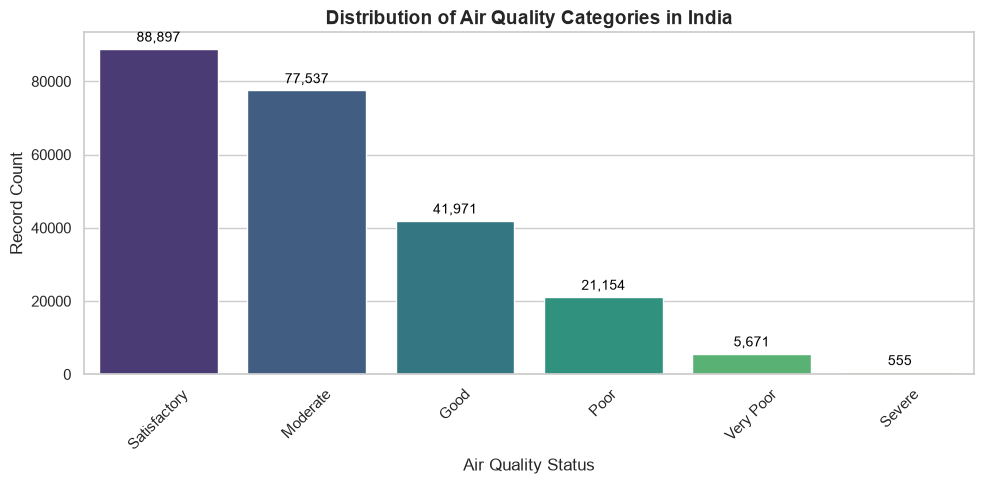

In [18]:
plt.figure(figsize=(10, 5))
status_counts = df_cleaned['air_quality_status'].value_counts()
ax = sns.barplot(x=status_counts.index, y=status_counts.values, palette="viridis")

plt.title("Distribution of Air Quality Categories in India", fontsize=14, fontweight='bold')
plt.xlabel("Air Quality Status", fontsize=12)
plt.ylabel("Record Count", fontsize=12)
plt.xticks(rotation=45)

# Annotate counts on top of bars
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontsize=10, color='black', xytext=(0, 3), 
                textcoords='offset points')

plt.tight_layout()
plt.show()

Visualization – Top 10 Most Polluted States by Average AQI

In [ ]:
plt.figure(figsize=(12, 6))
top_states = df_cleaned.groupby('state')['aqi_value'].mean().sort_values(ascending=False).head(10)
ax = sns.barplot(x=top_states.index, y=top_states.values, palette="magma")

plt.title("Top 10 Most Polluted States by Average AQI", fontsize=14, fontweight='bold')
plt.xlabel("State", fontsize=12)
plt.ylabel("Average AQI Value", fontsize=12)
plt.xticks(rotation=45, ha='right')

for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}", 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontsize=10, color='black', xytext=(0, 3), 
                textcoords='offset points')

plt.tight_layout()
plt.show()

Visualization – Prominent Pollutants Frequency

C:\Users\prath\AppData\Local\Temp\ipykernel_17280\515529998.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=pollutant_counts.index, y=pollutant_counts.values, palette="crest")


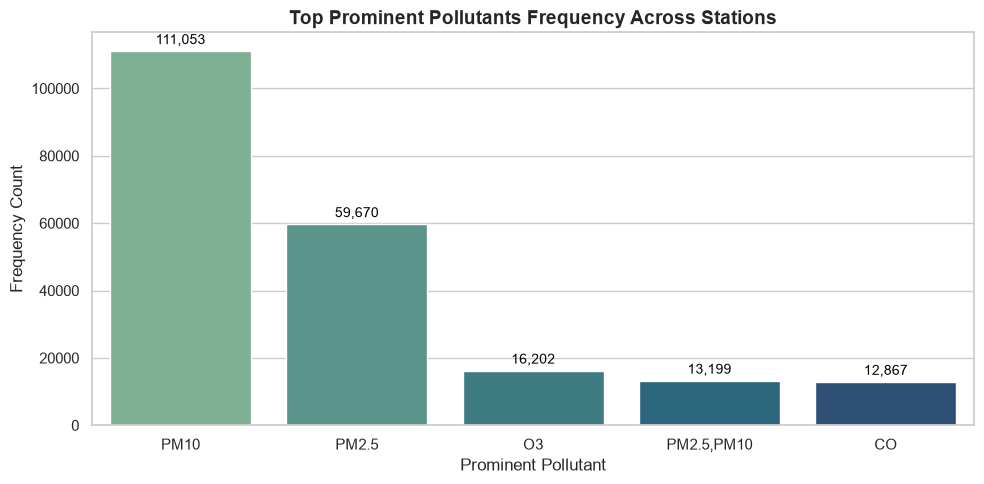

In [19]:
plt.figure(figsize=(10, 5))
pollutant_counts = df_cleaned['prominent_pollutants'].value_counts().head(5)
ax = sns.barplot(x=pollutant_counts.index, y=pollutant_counts.values, palette="crest")

plt.title("Top Prominent Pollutants Frequency Across Stations", fontsize=14, fontweight='bold')
plt.xlabel("Prominent Pollutant", fontsize=12)
plt.ylabel("Frequency Count", fontsize=12)

for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontsize=10, color='black', xytext=(0, 3), 
                textcoords='offset points')

plt.tight_layout()
plt.show()

Save Processed Cleaned Dataset

In [20]:
# Ensure processed directory exists and save cleaned CSV
processed_path = config['paths']['processed_data']
os.makedirs(os.path.dirname(processed_path), exist_ok=True)
df_cleaned.to_csv(processed_path, index=False)

print(f"Cleaned dataset successfully exported to: {processed_path}")

Cleaned dataset successfully exported to: ../data/processed/cleaned_aqi.csv
